In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

df = pd.read_csv("feature_engineered_transactions.csv")
df["transaction_date"] = pd.to_datetime(df["transaction_date"])

y = df["is_fraud"]
X = df.drop(columns=["is_fraud", "transaction_id", "customer_id", "transaction_date", "transaction_time"])
X = X.drop(columns=["customer_avg_amount"])
X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

rf_model = RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42)
rf_model.fit(X_train_scaled, y_train)

print("Setup complete — model retrained, ready for SHAP")

Setup complete — model retrained, ready for SHAP


In [2]:
!pip install shap

In [3]:
import shap

In [4]:
# TreeExplainer is a version of SHAP specifically optimized for tree-based models
# like Random Forest — much faster than the general-purpose SHAP method
explainer = shap.TreeExplainer(rf_model)

print("Explainer ready")

Explainer ready


In [5]:
explainer = shap.TreeExplainer(rf_model, feature_perturbation="tree_path_dependent")

# start much smaller to confirm it actually works at all — just 50 rows first
X_sample = X_test.iloc[:50]

shap_values = explainer.shap_values(X_sample, check_additivity=False)

print("SHAP values calculated")

SHAP values calculated


In [6]:
import shap
import sklearn
print("shap version:", shap.__version__)
print("sklearn version:", sklearn.__version__)

shap version: 0.52.0
sklearn version: 1.9.1


In [7]:
importances = pd.Series(rf_model.feature_importances_, index=X_train.columns)
importances = importances.sort_values(ascending=False)
print(importances.head(15))

transaction_amount             0.108065
credit_score                   0.087569
amount_to_balance_ratio        0.087300
account_balance                0.087248
days_since_last_transaction    0.077812
amount_vs_customer_avg         0.074242
transaction_hour               0.063451
customer_transaction_count     0.043593
emi_amount                     0.035679
account_type_Savings           0.012320
channel_Mobile_App             0.011026
channel_Web                    0.010470
state_Maharashtra              0.010064
account_type_Salary            0.010015
state_Karnataka                0.009219
dtype: float64


In [8]:
!pip install shap==0.44.1

  Using cached shap-0.44.1.tar.gz (1.1 MB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'done'
  Preparing metadata (pyproject.toml): started
  Preparing metadata (pyproject.toml): finished with status 'done'
  Using cached slicer-0.0.7-py3-none-any.whl.metadata (3.7 kB)
Using cached slicer-0.0.7-py3-none-any.whl (14 kB)
Failed to build shap


  error: subprocess-exited-with-error
  
  exit code: 1
  
  [214 lines of output]
  C:\Users\HP\AppData\Local\Temp\pip-build-env-fiiui9c0\overlay\Lib\site-packages\setuptools\config\_apply_pyprojecttoml.py:82: SetuptoolsDeprecationWarning: `project.license` as a TOML table is deprecated
  !!
  
          ********************************************************************************
          Please use a simple string containing a SPDX expression for `project.license`. You can also use `project.license-files`. (Both options available on setuptools>=77.0.0).
  
          By 2027-Feb-18, you need to update your project and remove deprecated calls
          or your builds will no longer be supported.
  
          See https://packaging.python.org/en/latest/guides/writing-pyproject-toml/#license for details.
          ********************************************************************************
  
  !!
    corresp(dist, value, root_dir)
  C:\Users\HP\AppData\Local\Temp\pip-build-env-f

In [10]:
explainer = shap.TreeExplainer(rf_model)
X_sample = X_test.iloc[:200]
shap_values = explainer.shap_values(X_sample)
print("Done")

Done


In [11]:
print(type(shap_values))

# for classification, shap_values is often a list [class_0_values, class_1_values]
# we only care about class 1 (fraud)
if isinstance(shap_values, list):
    print("It's a list with", len(shap_values), "elements")
    shap_values_fraud = shap_values[1]
else:
    shap_values_fraud = shap_values

print("Shape:", shap_values_fraud.shape)

<class 'numpy.ndarray'>
Shape: (200, 65, 2)


In [12]:
# shape is (200 transactions, 65 features, 2 classes)
# we want just the fraud class, which is index 1 (the last dimension)
shap_values_fraud = shap_values[:, :, 1]

print("Shape:", shap_values_fraud.shape)

Shape: (200, 65)


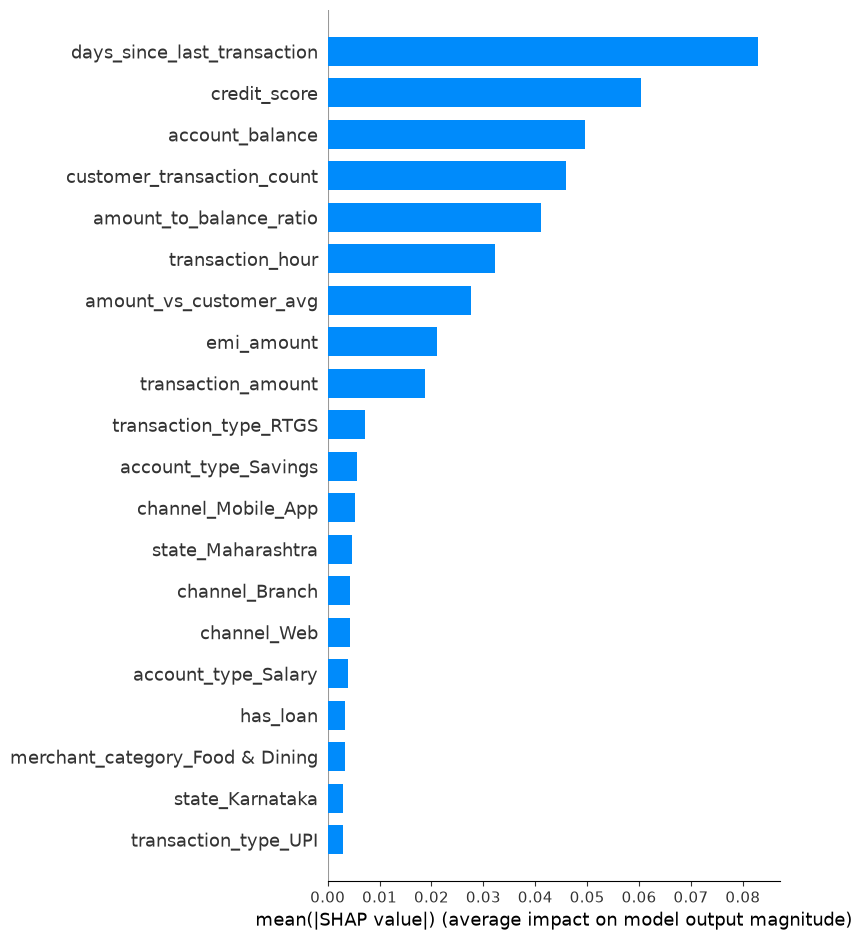

In [13]:
shap.summary_plot(shap_values_fraud, X_sample, plot_type="bar")

In [14]:
# find exceeds_balance's actual average SHAP value, even if it's not in the top 15
exceeds_balance_shap = shap_values_fraud[:, X_sample.columns.get_loc("exceeds_balance")]
print("Mean absolute SHAP value for exceeds_balance:", abs(exceeds_balance_shap).mean())

# compare to the topmost feature for scale
top_feature_shap = shap_values_fraud[:, X_sample.columns.get_loc("days_since_last_transaction")]
print("Mean absolute SHAP value for days_since_last_transaction:", abs(top_feature_shap).mean())

Mean absolute SHAP value for exceeds_balance: 0.001387780035458914
Mean absolute SHAP value for days_since_last_transaction: 0.08299881681648304


In [15]:
print(df[["exceeds_balance", "amount_to_balance_ratio"]].corr())

                         exceeds_balance  amount_to_balance_ratio
exceeds_balance                 1.000000                 0.536793
amount_to_balance_ratio         0.536793                 1.000000


In [16]:
# find the position of your best-known example: rank #1 from your investigation priority list — the one actual fraud case the model was most confident about (TXN000077173)
transaction_id_to_explain = "TXN000077173"

# find its row position within X_sample (only works if this transaction happens to be in your 200-row sample)
matching_rows = df.loc[X_sample.index]
row_position = matching_rows[matching_rows["transaction_id"] == transaction_id_to_explain].index

print(row_position)

Index([], dtype='int64')


In [17]:
# get fraud probability scores for just the 200 rows in your SHAP sample
sample_probs = rf_model.predict_proba(scaler.transform(X_sample))[:, 1]

# find the row with the highest fraud probability within this sample
best_row_position = sample_probs.argmax()

print("Highest fraud probability in sample:", sample_probs[best_row_position])
print("Row position:", best_row_position)

Highest fraud probability in sample: 0.25
Row position: 23


In [18]:
# look at this specific transaction's actual feature values
print(X_sample.iloc[23])

print("\n---SHAP values for this transaction---")
# pair each feature name with its SHAP value for row 23
explanation = pd.Series(shap_values_fraud[23], index=X_sample.columns)
explanation = explanation.sort_values(ascending=False)
print(explanation.head(10))

transaction_amount      642722.02
account_balance         348078.57
credit_score                  809
has_loan                        1
emi_amount                1123.32
                          ...    
channel_Mobile_App           True
channel_POS_Terminal        False
channel_Web                 False
kyc_status_Pending          False
kyc_status_Verified          True
Name: 237539, Length: 65, dtype: object

---SHAP values for this transaction---
transaction_type_Auto_Debit      0.000549
loan_type_No Loan                0.000531
transaction_status_Reversed     -0.000307
loan_type_Education             -0.000361
merchant_category_Education     -0.000395
state_Rajasthan                 -0.000481
state_Punjab                    -0.000558
merchant_category_Real Estate   -0.000590
loan_type_Unknown               -0.000620
merchant_category_Utilities     -0.000647
dtype: float64


In [19]:
explanation_abs = explanation.reindex(explanation.abs().sort_values(ascending=False).index)
print(explanation_abs.head(10))

days_since_last_transaction   -0.077510
customer_transaction_count    -0.060693
credit_score                  -0.054913
account_balance               -0.044173
amount_to_balance_ratio       -0.034102
emi_amount                    -0.033468
transaction_hour              -0.033433
transaction_amount            -0.019954
amount_vs_customer_avg        -0.013090
channel_Branch                -0.008740
dtype: float64


In [21]:
# expected_value is the model's baseline / average prediction, before any individual features adjust it
print("Base value:", explainer.expected_value)

Base value: [0.50004589 0.49995411]
